# ML Lab
## Name :- Pushkar Kolhe
## Roll no :- 51
## Section-Batch :- A-A4
## Lab-8

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("ai4i2020.csv")
df

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [ ]:
df.head

<bound method NDFrame.head of         UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0         1     M14860    M                298.1                    308.6   
1         2     L47181    L                298.2                    308.7   
2         3     L47182    L                298.1                    308.5   
3         4     L47183    L                298.2                    308.6   
4         5     L47184    L                298.2                    308.7   
...     ...        ...  ...                  ...                      ...   
9995   9996     M24855    M                298.8                    308.4   
9996   9997     H39410    H                298.9                    308.4   
9997   9998     M24857    M                299.0                    308.6   
9998   9999     H39412    H                299.0                    308.7   
9999  10000     M24859    M                299.0                    308.7   

      Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  \
0                       1551         42.8                0                0   
1                       1408         46.3                3                0   
2                       1498         49.4                5                0   
3                       1433         39.5                7                0   
4                       1408         40.0                9                0   
...                      ...          ...              ...              ...   
9995                    1604         29.5               14                0   
9996                    1632         31.8               17                0   
9997                    1645         33.4               22                0   
9998                    1408         48.5               25                0   
9999                    1500         40.2               30                0   

      TWF  HDF  PWF  OSF  RNF  
0       0    0    0    0    0  
1       0    0    0    0    0  
2       0    0    0    0    0  
3       0    0    0    0    0  
4       0    0    0    0    0  
...   ...  ...  ...  ...  ...  
9995    0    0    0    0    0  
9996    0    0    0    0    0  
9997    0    0    0    0    0  
9998    0    0    0    0    0  
9999    0    0    0    0    0  

[10000 rows x 14 columns]>

In [ ]:
df.tail

<bound method NDFrame.tail of         UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0         1     M14860    M                298.1                    308.6   
1         2     L47181    L                298.2                    308.7   
2         3     L47182    L                298.1                    308.5   
3         4     L47183    L                298.2                    308.6   
4         5     L47184    L                298.2                    308.7   
...     ...        ...  ...                  ...                      ...   
9995   9996     M24855    M                298.8                    308.4   
9996   9997     H39410    H                298.9                    308.4   
9997   9998     M24857    M                299.0                    308.6   
9998   9999     H39412    H                299.0                    308.7   
9999  10000     M24859    M                299.0                    308.7   

      Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  \
0                       1551         42.8                0                0   
1                       1408         46.3                3                0   
2                       1498         49.4                5                0   
3                       1433         39.5                7                0   
4                       1408         40.0                9                0   
...                      ...          ...              ...              ...   
9995                    1604         29.5               14                0   
9996                    1632         31.8               17                0   
9997                    1645         33.4               22                0   
9998                    1408         48.5               25                0   
9999                    1500         40.2               30                0   

      TWF  HDF  PWF  OSF  RNF  
0       0    0    0    0    0  
1       0    0    0    0    0  
2       0    0    0    0    0  
3       0    0    0    0    0  
4       0    0    0    0    0  
...   ...  ...  ...  ...  ...  
9995    0    0    0    0    0  
9996    0    0    0    0    0  
9997    0    0    0    0    0  
9998    0    0    0    0    0  
9999    0    0    0    0    0  

[10000 rows x 14 columns]>

In [ ]:
df.shape

(10000, 14)

In [ ]:
df.info

<bound method DataFrame.info of         UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0         1     M14860    M                298.1                    308.6   
1         2     L47181    L                298.2                    308.7   
2         3     L47182    L                298.1                    308.5   
3         4     L47183    L                298.2                    308.6   
4         5     L47184    L                298.2                    308.7   
...     ...        ...  ...                  ...                      ...   
9995   9996     M24855    M                298.8                    308.4   
9996   9997     H39410    H                298.9                    308.4   
9997   9998     M24857    M                299.0                    308.6   
9998   9999     H39412    H                299.0                    308.7   
9999  10000     M24859    M                299.0                    308.7   

      Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  \
0                       1551         42.8                0                0   
1                       1408         46.3                3                0   
2                       1498         49.4                5                0   
3                       1433         39.5                7                0   
4                       1408         40.0                9                0   
...                      ...          ...              ...              ...   
9995                    1604         29.5               14                0   
9996                    1632         31.8               17                0   
9997                    1645         33.4               22                0   
9998                    1408         48.5               25                0   
9999                    1500         40.2               30                0   

      TWF  HDF  PWF  OSF  RNF  
0       0    0    0    0    0  
1       0    0    0    0    0  
2       0    0    0    0    0  
3       0    0    0    0    0  
4       0    0    0    0    0  
...   ...  ...  ...  ...  ...  
9995    0    0    0    0    0  
9996    0    0    0    0    0  
9997    0    0    0    0    0  
9998    0    0    0    0    0  
9999    0    0    0    0    0  

[10000 rows x 14 columns]>

In [ ]:
X = df.drop('Machine failure', axis=1)

In [ ]:
y = df["Machine failure"]

In [ ]:
print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (10000, 13)
Output shape: (10000,)


In [ ]:
categorial_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 8000
Testing samples: 2000


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorial_features)
    ]
)

In [ ]:
linear_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="linear"))
    ]
)
linear_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='linear'))])

In [ ]:
y_pred_linear = linear_svm.predict(X_test)

In [ ]:
accuracy_linear = accuracy_score(y_test, y_pred_linear)
precision_linear = precision_score(y_test, y_pred_linear,zero_division=0)
recall_linear = recall_score(y_test, y_pred_linear,zero_division=0)
f1_linear = f1_score(y_test, y_pred_linear,zero_division=0)
print("Accuracy:", accuracy_linear)
print("Precision:", precision_linear)
print("Recall:", recall_linear)
print("F1 score:", f1_linear)

Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1 score: 0.0


In [ ]:
print(classification_report(y_test, y_pred_linear,target_names=["No failure","Failure"],zero_division=0))

              precision    recall  f1-score   support

  No failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



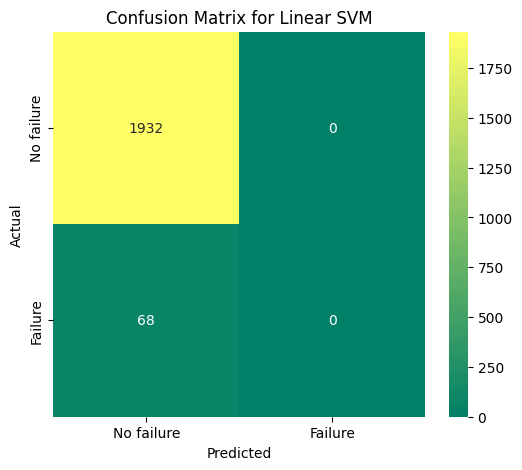

In [ ]:
cm_linear = confusion_matrix(y_test,y_pred_linear)
plt.figure(figsize=(6,5))
sns.heatmap(cm_linear,annot=True,fmt="d",cmap="summer",
            xticklabels=["No failure","Failure"],
            yticklabels=["No failure","Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Linear SVM")
plt.show()

In [ ]:
rbf_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="rbf"))
    ]
)
rbf_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC())])

In [ ]:
y_pred_rbf = rbf_svm.predict(X_test)

In [ ]:
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(y_test, y_pred_rbf,zero_division=0)
recall_rbf = recall_score(y_test, y_pred_rbf,zero_division=0)
f1_rbf = f1_score(y_test, y_pred_rbf,zero_division=0)
print("Accuracy:", accuracy_rbf)
print("Precision:", precision_rbf)
print("Recall:", recall_rbf)
print("F1 score:", f1_rbf)

Accuracy: 0.972
Precision: 0.875
Recall: 0.20588235294117646
F1 score: 0.3333333333333333


In [ ]:
print(classification_report(y_test, y_pred_rbf,target_names=["No failure","Failure"],zero_division=0))

              precision    recall  f1-score   support

  No failure       0.97      1.00      0.99      1932
     Failure       0.88      0.21      0.33        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.66      2000
weighted avg       0.97      0.97      0.96      2000



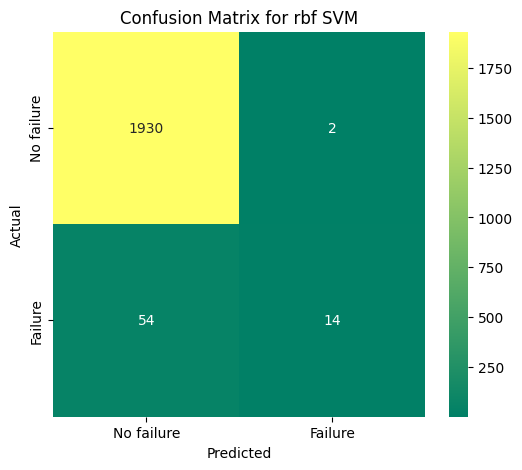

In [ ]:
cm_rbf = confusion_matrix(y_test,y_pred_rbf)
plt.figure(figsize=(6,5))
sns.heatmap(cm_rbf,annot=True,fmt="d",cmap="summer",
            xticklabels=["No failure","Failure"],
            yticklabels=["No failure","Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for rbf SVM")
plt.show()

In [ ]:
poly_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="poly"))
    ]
)
poly_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='poly'))])

In [ ]:
y_pred_poly = poly_svm.predict(X_test)

In [ ]:
accuracy_poly = accuracy_score(y_test, y_pred_poly)
precision_poly = precision_score(y_test, y_pred_poly,zero_division=0)
recall_poly = recall_score(y_test, y_pred_poly,zero_division=0)
f1_poly = f1_score(y_test, y_pred_poly,zero_division=0)
print("Accuracy:", accuracy_poly)
print("Precision:", precision_poly)
print("Recall:", recall_poly)
print("F1 score:", f1_poly)

Accuracy: 0.9745
Precision: 0.8695652173913043
Recall: 0.29411764705882354
F1 score: 0.43956043956043955


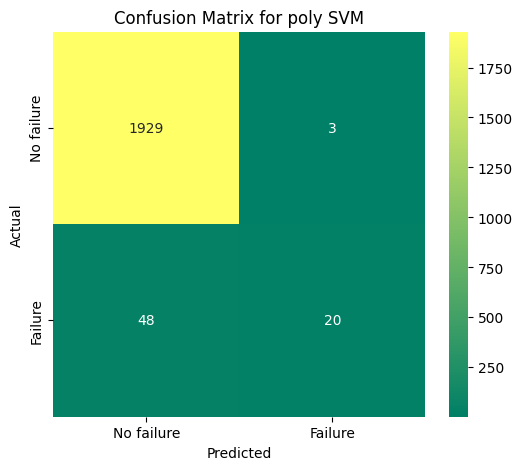

In [ ]:
cm_poly = confusion_matrix(y_test,y_pred_poly)
plt.figure(figsize=(6,5))
sns.heatmap(cm_poly,annot=True,fmt="d",cmap="summer",
            xticklabels=["No failure","Failure"],
            yticklabels=["No failure","Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for poly SVM")
plt.show()

In [ ]:
sigmoid_svm = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(kernel="sigmoid"))
    ]
)
sigmoid_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='sigmoid'))])

In [ ]:
y_pred_sigmoid = sigmoid_svm.predict(X_test)

In [ ]:
accuracy_sigmoid = accuracy_score(y_test, y_pred_sigmoid)
precision_sigmoid = precision_score(y_test, y_pred_sigmoid,zero_division=0)
recall_sigmoid = recall_score(y_test, y_pred_sigmoid,zero_division=0)
f1_sigmoid = f1_score(y_test, y_pred_sigmoid,zero_division=0)
print("Accuracy:", accuracy_sigmoid)
print("Precision:", precision_sigmoid)
print("Recall:", recall_sigmoid)
print("F1 score:", f1_sigmoid)

Accuracy: 0.945
Precision: 0.15
Recall: 0.1323529411764706
F1 score: 0.140625


In [ ]:
comparison = pd.DataFrame({
    "Kernel": ["Linear", "rbf", "poly","sigmoid"],
    "Accuracy": [accuracy_linear, accuracy_rbf, accuracy_poly,accuracy_sigmoid],
    "Precision": [precision_linear, precision_rbf, precision_poly,precision_sigmoid],
    "Recall": [recall_linear, recall_rbf, recall_poly,recall_sigmoid],
    "F1 score": [f1_linear, f1_rbf, f1_poly,f1_sigmoid]
})
comparison

,Kernel,Accuracy,Precision,Recall,F1 score
0,Linear,0.9660,0.000000,0.000000,0.000000
1,rbf,0.9720,0.875000,0.205882,0.333333
2,poly,0.9745,0.869565,0.294118,0.439560
3,sigmoid,0.9450,0.150000,0.132353,0.140625


In [ ]:
from sklearn.pipeline import Pipeline
pipeline = Pipeline(steps=[("preprocessor",preprocessor),("classifier",SVC())])

In [ ]:
param_grid = [
    {"classifier__kernel": ["linear"], "classifier__C": [0.1, 1, 10, 100]},
    {"classifier__kernel": ["rbf"], "classifier__C": [0.1, 1, 10, 100], "classifier__gamma": ["scale", "auto"]}
]

In [ ]:
grid_search = GridSearchCV(estimator=pipeline, param_grid=param_grid, cv=5, scoring="f1", n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['Air '
                                                                          'temperature '
                                                                          '[K]',
                                                                          'Process '
                                                                          'temperature '
                                                                          '[K]',
                                                                          'Rotational '
                                                                          'speed '
                                                                          '[rpm]',
                                                                          'Torque '
                                                                          '[Nm]',
                                                                          'Tool '
                                                                          'wear '
                                                                          '[min]']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['Type'])])),
                                       ('classifier', SVC())]),
             n_jobs=-1,
             param_grid=[{'classifier__C': [0.1, 1, 10, 100],
                          'classifier__kernel': ['linear']},
                         {'classifier__C': [0.1, 1, 10, 100],
                          'classifier__gamma': ['scale', 'auto'],
                          'classifier__kernel': ['rbf']}],
             scoring='f1', verbose=1)

In [ ]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}


In [ ]:
print("Best Cross-validation F1 Score:",grid_search.best_score_)

Best Cross-validation F1 Score: 0.7080372186703207


In [ ]:
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)


In [ ]:
accuracy_tuned = accuracy_score(y_test, y_pred_best)
precision_tuned = precision_score(y_test, y_pred_best, zero_division=0)
recall_tuned = recall_score(y_test, y_pred_best, zero_division=0)
f1_tuned = f1_score(y_test, y_pred_best, zero_division=0)

print("Tuned SVM results:")
print("Accuracy:", accuracy_tuned)
print("Precision:", precision_tuned)
print("Recall:", recall_tuned)
print("F1 score:", f1_tuned)

Tuned SVM results:
Accuracy: 0.98
Precision: 0.7592592592592593
Recall: 0.6029411764705882
F1 score: 0.6721311475409836
